# Mitigation lever plots

One plot per mitigation lever: **n_bin**, **PB**, **hm_cell**, **ROI**, **nfields** and **spws**. All formulas are imported from `smart_size_mitigation_heuristics.py`, so the plots always match what the planner uses.

Each plot shows the fractional size reduction a lever can deliver. The figures are saved as PNGs in `PLOT_DIR`, defined in the first code cell: a directory one level above the code directory.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from smart_size_mitigation_heuristics import (
    mitigation_nbin,
    mitigation_pb,
    mitigation_cell,
    mitigation_roi,
    mitigation_fields,
    mitigation_spws,
)

# Directory for the saved figures: one level above the code directory
# (the directory this notebook lives in). Change the name here if needed.
PLOT_DIR = Path.cwd().parent / "70_results/plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Saving figures to: {PLOT_DIR}")

# Function to label a curve at a given x position, rotated to match the slope of the curve there
def label_along_curve(ax, x, y, x_label, text, color, side=1, offset_pts=8, fontsize=9):
    """Write `text` next to the curve (x, y) at x = x_label, rotated so that it
    runs parallel to the curve there (the slope is taken in display
    coordinates, i.e. as it looks on the plot). side=+1 puts the label above
    the curve, side=-1 below it. Call after fig.tight_layout(), once the axes
    size is final."""
    x, y = np.asarray(x), np.asarray(y)
    eps = 0.01 * (x[-1] - x[0])
    (px0, py0), (px1, py1) = ax.transData.transform(
        [(x_label - eps, np.interp(x_label - eps, x, y)),
         (x_label + eps, np.interp(x_label + eps, x, y))]
    )
    angle = np.degrees(np.arctan2(py1 - py0, px1 - px0))
    nx, ny = -np.sin(np.radians(angle)), np.cos(np.radians(angle))  # unit normal, pointing up
    ax.annotate(
        text, xy=(x_label, np.interp(x_label, x, y)),
        xytext=(side * offset_pts * nx, side * offset_pts * ny), textcoords="offset points",
        rotation=angle, rotation_mode="anchor", ha="center", va="center",
        fontsize=fontsize, color=color,
    )

Saving figures to: /Users/lneumann/work/projects/alma_pipeline_smart_mitigation/70_results/plots


## n_bin mitigation

Lookup, not a continuous function: nchan in {7680, 3840} is always eligible for nbin=2 (mitigation 0.5). nchan in {1920, 960, 480} is only eligible if the channel-width ratio condition is met; otherwise the mitigation is 0.

   nchan   mitigation (ratio unmet)   mitigation (ratio met)
     480                      0.000                    0.500
     960                      0.000                    0.500
    1920                      0.000                    0.500
    3840                      0.500                    0.500
    7680                      0.500                    0.500


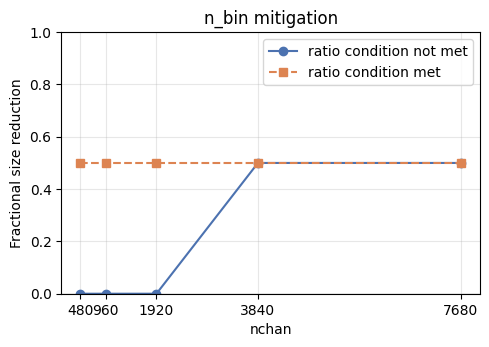

In [2]:
eligible_nchans = [480, 960, 1920, 3840, 7680]

mitigation_ratio_false = [mitigation_nbin(n, ratio_satisfied=False) for n in eligible_nchans]
mitigation_ratio_true = [mitigation_nbin(n, ratio_satisfied=True) for n in eligible_nchans]

print(f"{'nchan':>8} {'mitigation (ratio unmet)':>26} {'mitigation (ratio met)':>24}")
for n, m_false, m_true in zip(eligible_nchans, mitigation_ratio_false, mitigation_ratio_true):
    print(f"{n:>8} {m_false:>26.3f} {m_true:>24.3f}")

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(eligible_nchans, mitigation_ratio_false, marker="o", label="ratio condition not met", color="#4C72B0")
ax.plot(eligible_nchans, mitigation_ratio_true, marker="s", linestyle="--", label="ratio condition met", color="#DD8452")
ax.set_xticks(eligible_nchans)
ax.set_xlabel("nchan")
ax.set_ylabel("Fractional size reduction")
ax.set_title("n_bin mitigation")
ax.set_ylim(0, 1)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "nbin_mitigation_sizes.png", dpi=150)
plt.show()

## PB mitigation

Mosaics: never mitigated (0). Single pointings: the field of view can be tightened down to a floor of PB = 0.7; the reduction is `1 - (0.7/PB)^2` above the floor and 0 at or below it.

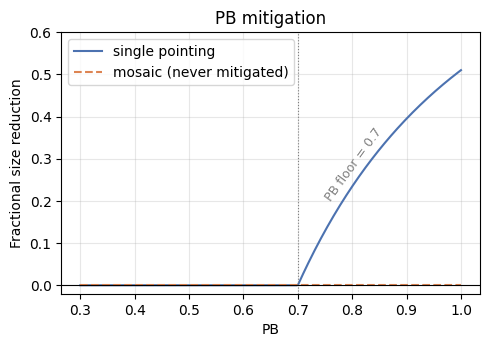

In [3]:
PB_FLOOR = 0.7

pb_values = np.linspace(0.3, 1.0, 300)
mitigation_single_pointing = [mitigation_pb(pb, is_mosaic=False) for pb in pb_values]
mitigation_mosaic = [mitigation_pb(pb, is_mosaic=True) for pb in pb_values]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(pb_values, mitigation_single_pointing, label="single pointing", color="#4C72B0")
ax.plot(pb_values, mitigation_mosaic, label="mosaic (never mitigated)", color="#DD8452", linestyle="--")
ax.axvline(PB_FLOOR, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("PB")
ax.set_ylabel("Fractional size reduction")
ax.set_title("PB mitigation")
ax.set_ylim(-0.02, 0.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
label_along_curve(ax, pb_values, mitigation_single_pointing, PB_FLOOR + 0.12,
                  f"PB floor = {PB_FLOOR}", color="gray", side=1)
fig.savefig(PLOT_DIR / "pb_mitigation_sizes.png", dpi=150)
plt.show()

## hm_cell mitigation

The cell size (in pixels per beam, ppb) can be tightened down to a floor of 3.25 ppb for robust = 2.0 (PIPE-107) and 3.0 ppb otherwise. Above the floor the reduction is `1 - (floor/ppb)^2`; at or below it, 0.

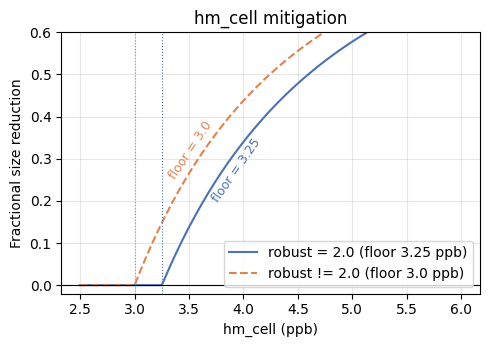

In [4]:
CELL_FLOOR_ROBUST_2 = 3.25
CELL_FLOOR_DEFAULT = 3.0

ppb_values = np.linspace(2.5, 6.0, 300)
mitigation_robust2 = [mitigation_cell(ppb, robust=2.0) for ppb in ppb_values]
mitigation_default = [mitigation_cell(ppb, robust=None) for ppb in ppb_values]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(ppb_values, mitigation_robust2, label="robust = 2.0 (floor 3.25 ppb)", color="#4C72B0")
ax.plot(ppb_values, mitigation_default, label="robust != 2.0 (floor 3.0 ppb)", color="#DD8452", linestyle="--")
ax.axvline(CELL_FLOOR_ROBUST_2, color="#4C72B0", linewidth=0.8, linestyle=":")
ax.axvline(CELL_FLOOR_DEFAULT, color="#DD8452", linewidth=0.8, linestyle=":")
ax.set_xlabel("hm_cell (ppb)")
ax.set_ylabel("Fractional size reduction")
ax.set_title("hm_cell mitigation")
ax.set_ylim(-0.02, 0.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
label_along_curve(ax, ppb_values, mitigation_default, CELL_FLOOR_DEFAULT + 0.6,
                  f"floor = {CELL_FLOOR_DEFAULT}", color="#DD8452", side=1)
label_along_curve(ax, ppb_values, mitigation_robust2, CELL_FLOOR_ROBUST_2 + 0.6,
                  f"floor = {CELL_FLOOR_ROBUST_2}", color="#4C72B0", side=-1)
fig.savefig(PLOT_DIR / "hm_cell_mitigation_sizes.png", dpi=150)
plt.show()

## spw mitigation

Linear in the number of spectral windows removed, assuming equal-sized spws: `n_removed / n_total`. The representative spw is always kept, so `n_spws_removed` runs from 0 (none) to `n_spws_total - 1` (maximum mitigation). The planner itself uses the actual per-spw sizes; this is the idealised curve.

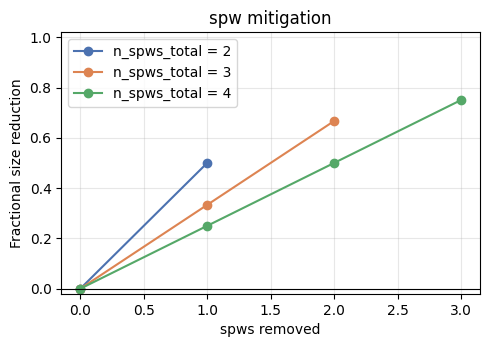

In [5]:
n_spws_total_values = [2, 3, 4]
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
for n_total, color in zip(n_spws_total_values, colors):
    n_removed_values = np.arange(0, n_total)
    mitigation_removed = [mitigation_spws(n_total, n_removed) for n_removed in n_removed_values]
    ax.plot(n_removed_values, mitigation_removed, marker="o", label=f"n_spws_total = {n_total}", color=color)
ax.set_xlabel("spws removed")
ax.set_ylabel("Fractional size reduction")
ax.set_title("spw mitigation")
ax.set_ylim(-0.02, 1.02)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "spws_mitigation_sizes.png", dpi=150)
plt.show()

## nfields mitigation

Linear in the number of fields dropped, assuming equal-sized fields: `n_removed / n_total`. At least one field (the representative) is always kept, so `n_fields_removed` runs from 0 (none) to `n_fields_total - 1` (maximum mitigation).

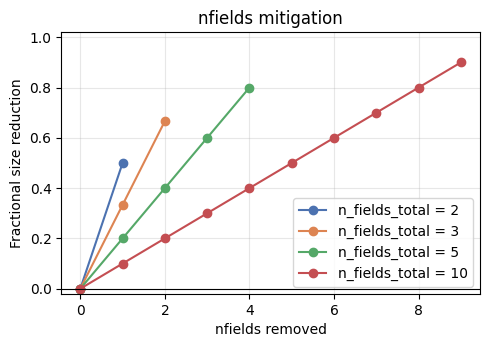

In [6]:
n_fields_total_values = [2, 3, 5, 10]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
for n_total, color in zip(n_fields_total_values, colors):
    n_removed_values = np.arange(0, n_total)
    mitigation_removed = [mitigation_fields(n_total, n_total - n_removed) for n_removed in n_removed_values]
    ax.plot(n_removed_values, mitigation_removed, marker="o", label=f"n_fields_total = {n_total}", color=color)
ax.set_xlabel("nfields removed")
ax.set_ylabel("Fractional size reduction")
ax.set_title("nfields mitigation")
ax.set_ylim(-0.02, 1.02)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "nfields_mitigation_sizes.png", dpi=150)
plt.show()

## ROI mitigation

Not yet implemented in the pipeline (the planner keeps it off unless `use_roi=True`). A channel selection is a 1-D cut, so the reduction is linear: `1 - n_roi/n_total`.

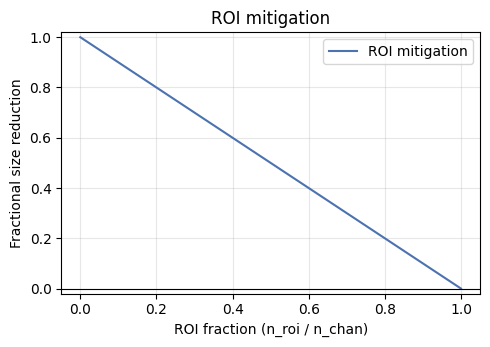

In [7]:
roi_fractions = np.linspace(0.0, 1.0, 300)
mitigation_values = [mitigation_roi(f, 1.0) for f in roi_fractions]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(roi_fractions, mitigation_values, label="ROI mitigation", color="#4C72B0")
ax.set_xlabel("ROI fraction (n_roi / n_chan)")
ax.set_ylabel("Fractional size reduction")
ax.set_title("ROI mitigation")
ax.set_ylim(-0.02, 1.02)
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "roi_mitigation_sizes.png", dpi=150)
plt.show()